# Лабораторна робота 3. Машинне навчання. Лінійна регресія

**Виконала:** Сєднєва Уляна, група 4-10
**Варіант:** 19
**Репозиторій GitHub:** https://github.com/UlyanaSedneva/-3.git

In [1]:
# Підключення бібліотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes, fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

pd.set_option('display.float_format', lambda x: f'{x:.3f}')
RANDOM_STATE = 19   # варіант 19 - для відтворюваності результатів

---
# Завдання 1. Diabetes Dataset

Датасет містить 10 фізіологічних змінних (вік, стать, індекс маси тіла, артеріальний тиск та 6 показників аналізу крові) і цільову змінну `target` — кількісну міру прогресу діабету через рік після вихідних даних.

In [2]:
# Завантаження датасету
# scaled=False - беремо вихідні (не нормовані) значення, щоб самостійно виконати всі кроки попереднього аналізу
diabetes = load_diabetes(as_frame=True, scaled=False)
db = diabetes.frame.copy()
print('Розмір датасету:', db.shape)
print('Ознаки:', list(diabetes.feature_names))

Розмір датасету: (442, 11)
Ознаки: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [3]:
# 1. Вивести перших 5 рядків
db.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.000,2.000,32.100,101.000,157.000,93.200,38.000,4.000,4.860,87.000,151.000
1,48.000,1.000,21.600,87.000,183.000,103.200,70.000,3.000,3.892,69.000,75.000
2,72.000,2.000,30.500,93.000,156.000,93.600,41.000,4.000,4.673,85.000,141.000
3,24.000,1.000,25.300,84.000,198.000,131.400,40.000,5.000,4.890,89.000,206.000
4,50.000,1.000,23.000,101.000,192.000,125.400,52.000,4.000,4.290,80.000,135.000


In [4]:
# 2. Перевірити наявність пропусків. У разі виявлення замінити на середнє значення
print('Пропущені значення:\n', db.isna().sum())
db = db.fillna(db.mean(numeric_only=True))
print('\nПропусків після заміни:', db.isna().sum().sum())

Пропущені значення:
 age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Пропусків після заміни: 0


In [5]:
# 3. Перевірити наявність дублікатів, при виявленні - видалити
print('Кількість дублікатів:', db.duplicated().sum())
db = db.drop_duplicates().reset_index(drop=True)
print('Розмір після перевірки:', db.shape)

Кількість дублікатів: 0
Розмір після перевірки: (442, 11)


In [6]:
# 4. Замінити бінарні ознаки. У стовпчику "стать" спочатку перевіряємо унікальні значення
print('Унікальні значення sex:', db['sex'].unique())
db['sex'] = db['sex'].map({1.0: 0, 2.0: 1})
print('Після заміни:', db['sex'].unique(), '(1 -> 0, 2 -> 1)')

Унікальні значення sex: [2. 1.]
Після заміни: [1 0] (1 -> 0, 2 -> 1)


In [7]:
# 5. Перевірити тип даних. При необхідності замінити тип даних на числовий
print(db.dtypes)
db = db.apply(pd.to_numeric, errors='coerce')
print('\nУсі стовпці числові:', all(pd.api.types.is_numeric_dtype(t) for t in db.dtypes))

age       float64
sex         int64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

Усі стовпці числові: True


Кореляція з target (за спаданням):
bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395
Name: target, dtype: float64


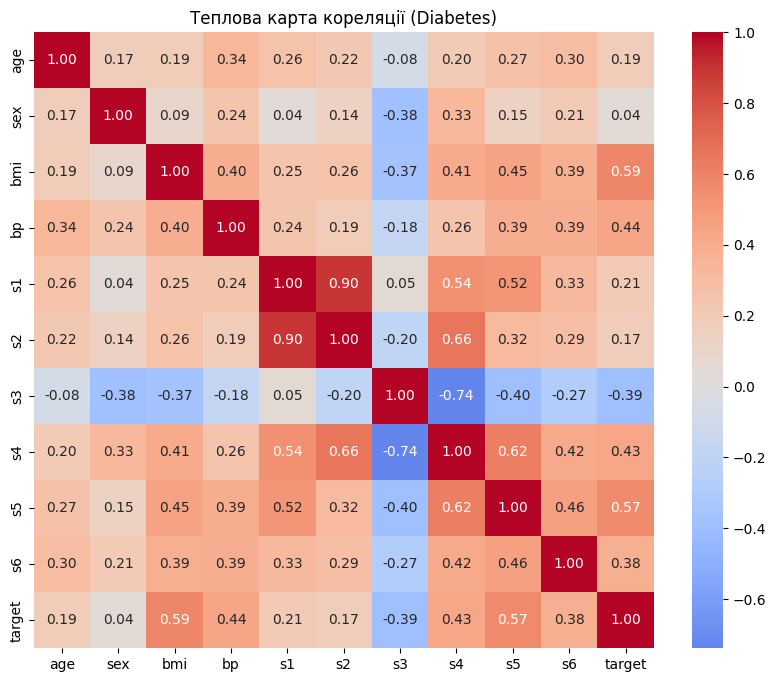

Ознаки за силою зв'язку (|r|): ['bmi', 's5', 'bp', 's4', 's3', 's6', 's1', 'age', 's2', 'sex']


In [8]:
# 6. Кореляція між прогресом діабету та іншими ознаками (за спаданням)
corr_target = db.corr()['target'].drop('target').sort_values(ascending=False)
print('Кореляція з target (за спаданням):')
print(corr_target)

# Теплова карта кореляції
plt.figure(figsize=(10, 8))
sns.heatmap(db.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Теплова карта кореляції (Diabetes)')
plt.show()

# для відбору ознак важлива сила зв'язку, тому далі впорядковуємо за модулем кореляції
corr_abs = corr_target.abs().sort_values(ascending=False)
print('Ознаки за силою зв\'язку (|r|):', list(corr_abs.index))

In [9]:
# 7. Масштабування ознак (StandardScaler: середнє 0, стандартне відхилення 1)
X_db = db.drop(columns='target')
y_db = db['target']

scaler_db = StandardScaler()
X_db_scaled = pd.DataFrame(scaler_db.fit_transform(X_db), columns=X_db.columns)
X_db_scaled.describe().loc[['mean', 'std']]

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
mean,0.000,-0.000,0.000,0.000,-0.000,-0.000,-0.000,-0.000,0.000,0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001


In [10]:
# 8. Поділ на тренувальну і тестову вибірки (80 % / 20 %)
# Щоб інформація з тестових даних не потрапила в модель, масштабувальник
# навчаємо лише на тренувальній вибірці і застосовуємо до тестової
X_tr_raw, X_te_raw, y_tr_db, y_te_db = train_test_split(X_db, y_db, test_size=0.2, random_state=RANDOM_STATE)
scaler_db = StandardScaler().fit(X_tr_raw)
X_tr_db = pd.DataFrame(scaler_db.transform(X_tr_raw), columns=X_db.columns, index=X_tr_raw.index)
X_te_db = pd.DataFrame(scaler_db.transform(X_te_raw), columns=X_db.columns, index=X_te_raw.index)
print('Тренувальна вибірка:', X_tr_db.shape, ' Тестова вибірка:', X_te_db.shape)

Тренувальна вибірка: (353, 10)  Тестова вибірка: (89, 10)


,k,Додана ознака,R2_CV_LinReg,R2_CV_RandomForest
0,1,bmi,0.319,0.262
1,2,s5,0.439,0.459
2,3,bp,0.446,0.476
3,4,s4,0.443,0.480
4,5,s3,0.458,0.475
5,6,s6,0.455,0.479
6,7,s1,0.457,0.484
7,8,age,0.455,0.482
8,9,s2,0.461,0.484
9,10,sex,0.469,0.488


Оптимальне число ознак для лінійної регресії: 10 -> ['bmi', 's5', 'bp', 's4', 's3', 's6', 's1', 'age', 's2', 'sex']
Оптимальне число ознак для RandomForest: 10 -> ['bmi', 's5', 'bp', 's4', 's3', 's6', 's1', 'age', 's2', 'sex']


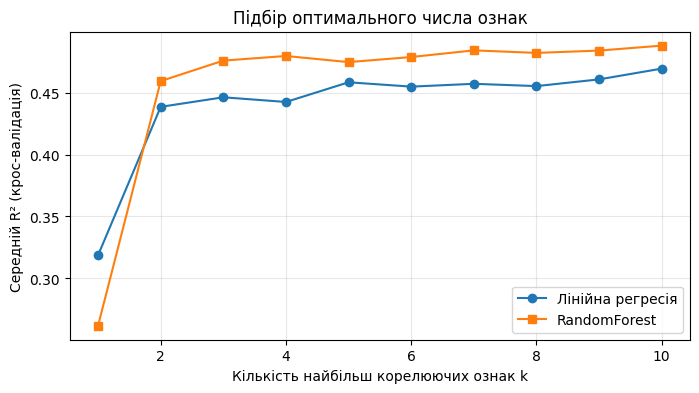


Коефіцієнти лінійної регресії (на масштабованих ознаках):
s1    -47.360
s5     40.730
s2     30.650
bmi    24.750
bp     13.300
s4     10.630
s3      9.200
sex    -8.870
age    -2.140
s6      1.500
dtype: float64


In [11]:
# 9. Моделі лінійної регресії та RandomForest на основі найбільш корелюючих ознак
# Оптимальне число ознак підбираємо крос-валідацією (5 блоків) на тренувальній вибірці:
# беремо k ознак з найбільшим |r| і дивимось, при якому k середній R2 найвищий
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# у листку дерева щонайменше 5 пацієнтів - це зменшує перенавчання лісу на малому датасеті (442 рядки)
rf_params = dict(n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)
rows = []
for k in range(1, len(corr_abs) + 1):
    feats = list(corr_abs.index[:k])
    lr_cv = cross_val_score(LinearRegression(), X_tr_db[feats], y_tr_db, cv=kf, scoring='r2').mean()
    rf_cv = cross_val_score(RandomForestRegressor(**rf_params),
                            X_tr_db[feats], y_tr_db, cv=kf, scoring='r2').mean()
    rows.append({'k': k, 'Додана ознака': feats[-1], 'R2_CV_LinReg': lr_cv, 'R2_CV_RandomForest': rf_cv})
k_table = pd.DataFrame(rows)
display(k_table)

k_lr = int(k_table.loc[k_table['R2_CV_LinReg'].idxmax(), 'k'])
k_rf = int(k_table.loc[k_table['R2_CV_RandomForest'].idxmax(), 'k'])
feats_lr = list(corr_abs.index[:k_lr])
feats_rf = list(corr_abs.index[:k_rf])
print(f'Оптимальне число ознак для лінійної регресії: {k_lr} -> {feats_lr}')
print(f'Оптимальне число ознак для RandomForest: {k_rf} -> {feats_rf}')

plt.figure(figsize=(8, 4))
plt.plot(k_table['k'], k_table['R2_CV_LinReg'], 'o-', label='Лінійна регресія')
plt.plot(k_table['k'], k_table['R2_CV_RandomForest'], 's-', label='RandomForest')
plt.xlabel('Кількість найбільш корелюючих ознак k')
plt.ylabel('Середній R² (крос-валідація)')
plt.title('Підбір оптимального числа ознак')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# Навчання фінальних моделей
lr_db = LinearRegression().fit(X_tr_db[feats_lr], y_tr_db)
rf_db = RandomForestRegressor(**rf_params).fit(X_tr_db[feats_rf], y_tr_db)
pred_lr_db = lr_db.predict(X_te_db[feats_lr])
pred_rf_db = rf_db.predict(X_te_db[feats_rf])

print('\nКоефіцієнти лінійної регресії (на масштабованих ознаках):')
print(pd.Series(lr_db.coef_, index=feats_lr).sort_values(key=abs, ascending=False).round(2))

In [12]:
# 10. Коефіцієнт детермінації R2 та середньоквадратична помилка MSE на тестовій вибірці
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'R2': r2_score(y_true, y_pred), 'MSE': mse, 'RMSE': np.sqrt(mse)}

res_db = pd.DataFrame({
    f'Лінійна регресія ({k_lr} ознак)': metrics(y_te_db, pred_lr_db),
    f'RandomForest ({k_rf} ознак)': metrics(y_te_db, pred_rf_db),
}).T
display(res_db)
best_db = res_db['R2'].idxmax()
print(f"Відповідь: краща модель - {best_db}, R2 = {res_db.loc[best_db, 'R2']:.3f}, "
      f"MSE = {res_db.loc[best_db, 'MSE']:.1f}")
print(f'Для порівняння: стандартне відхилення target на тесті = {y_te_db.std():.1f}')

,R2,MSE,RMSE
Лінійна регресія (10 ознак),0.477,3107.565,55.746
RandomForest (10 ознак),0.317,4061.719,63.732


Відповідь: краща модель - Лінійна регресія (10 ознак), R2 = 0.477, MSE = 3107.6
Для порівняння: стандартне відхилення target на тесті = 77.5


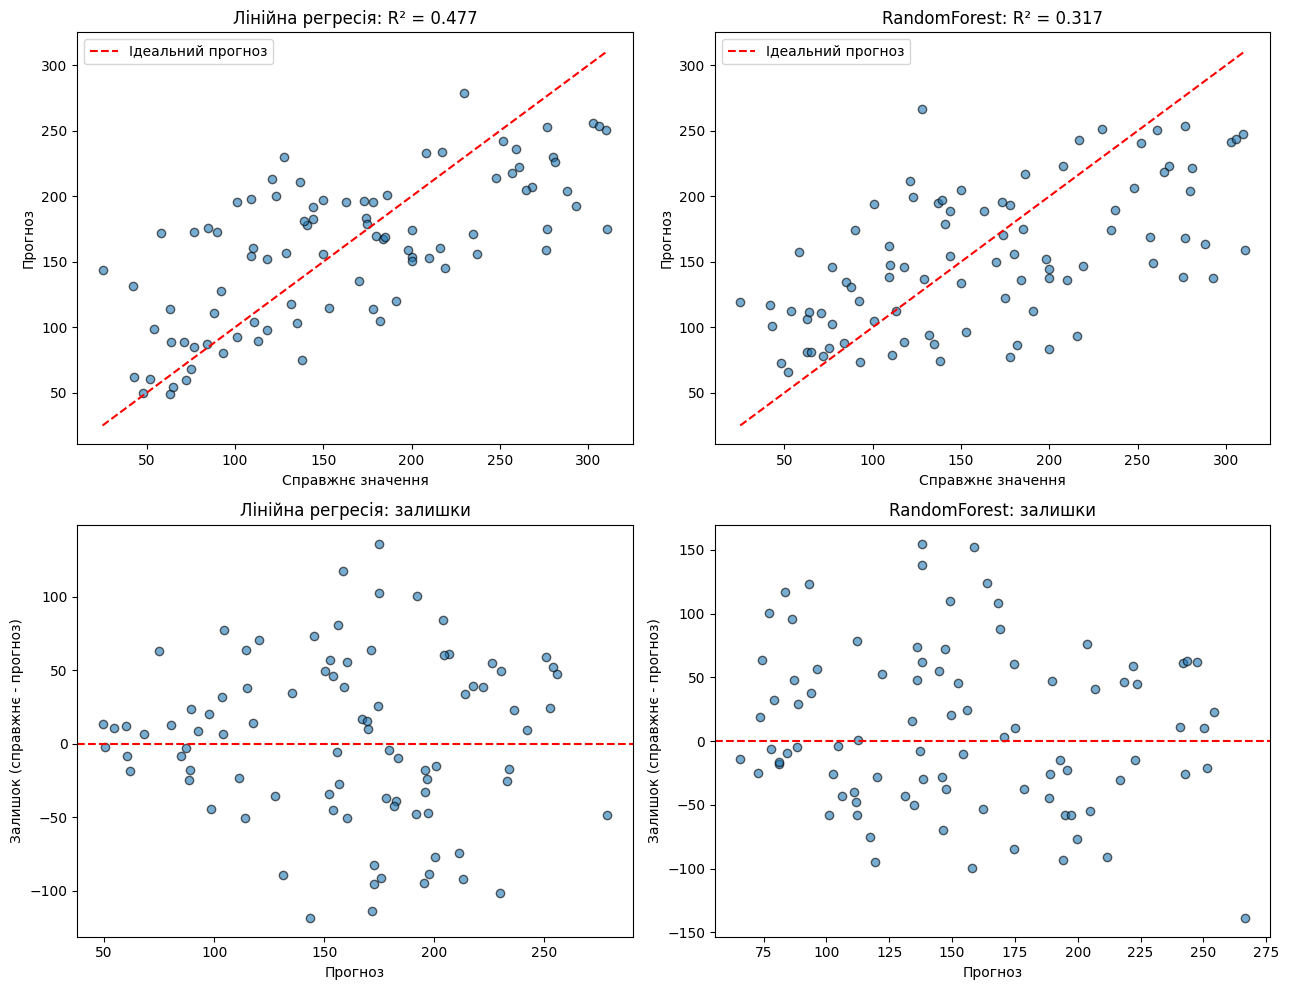

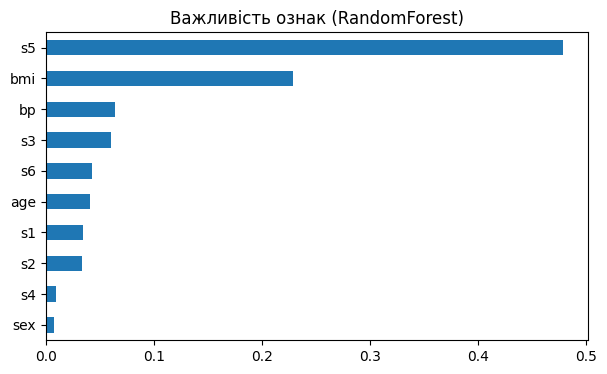

In [13]:
# 11. Графіки: прогноз проти справжніх значень і залишки
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for col, (name, pred) in enumerate([('Лінійна регресія', pred_lr_db), ('RandomForest', pred_rf_db)]):
    ax = axes[0, col]
    ax.scatter(y_te_db, pred, alpha=0.6, edgecolor='k')
    lims = [y_te_db.min(), y_te_db.max()]
    ax.plot(lims, lims, 'r--', label='Ідеальний прогноз')
    ax.set_xlabel('Справжнє значення'); ax.set_ylabel('Прогноз')
    ax.set_title(f'{name}: R² = {r2_score(y_te_db, pred):.3f}'); ax.legend()

    ax = axes[1, col]
    ax.scatter(pred, y_te_db - pred, alpha=0.6, edgecolor='k')
    ax.axhline(0, color='r', ls='--')
    ax.set_xlabel('Прогноз'); ax.set_ylabel('Залишок (справжнє - прогноз)')
    ax.set_title(f'{name}: залишки')
plt.tight_layout(); plt.show()

# Важливість ознак у RandomForest
pd.Series(rf_db.feature_importances_, index=feats_rf).sort_values().plot.barh(figsize=(7, 4), title='Важливість ознак (RandomForest)')
plt.show()

In [14]:
# 12. Справжні та прогнозовані значення (перші 15 рядків тестової вибірки)
compare_db = pd.DataFrame({
    'Справжнє': y_te_db.values,
    'Прогноз_LinReg': pred_lr_db.round(1),
    'Прогноз_RF': pred_rf_db.round(1),
})
compare_db['Похибка_LinReg'] = (compare_db['Справжнє'] - compare_db['Прогноз_LinReg']).round(1)
compare_db['Похибка_RF'] = (compare_db['Справжнє'] - compare_db['Прогноз_RF']).round(1)
compare_db.head(15)

,Справжнє,Прогноз_LinReg,Прогноз_RF,Похибка_LinReg,Похибка_RF
0,268.000,206.800,223.500,61.200,44.500
1,303.000,255.700,241.800,47.300,61.200
2,186.000,201.000,216.800,-15.000,-30.800
3,170.000,135.200,149.700,34.800,20.300
4,109.000,154.200,138.400,-45.200,-29.400
5,85.000,176.000,134.800,-91.000,-49.800
6,280.000,230.300,203.700,49.700,76.300
7,276.000,158.700,138.100,117.300,137.900
8,63.000,49.300,80.900,13.700,-17.900
9,173.000,196.800,195.800,-23.800,-22.800


### Висновок до завдання 1

Датасет Diabetes містить дані 442 пацієнтів: 10 ознак і цільову змінну `target`, тобто показник прогресу діабету через рік. Пропусків і дублікатів у даних немає, усі стовпці числові. Бінарною ознакою є лише стать: її значення 1 і 2 замінено на 0 і 1.

Найсильніше з прогресом діабету пов'язані індекс маси тіла `bmi` (r = 0,59), показник крові `s5` (r = 0,57), артеріальний тиск `bp` (r = 0,44) та `s4` (r = 0,43). Показник `s3` має помірну від'ємну кореляцію (r = −0,40): чим він вищий, тим повільніше прогресує хвороба. Стать майже не пов'язана з цільовою змінною (r = 0,04).

Ознаки масштабовано (StandardScaler), а дані поділено на тренувальну (353) і тестову (89) вибірки. Оптимальне число ознак підбирали крос-валідацією, додаючи їх по одній у порядку спадання |r|. Двох ознак (`bmi` і `s5`) вже достатньо, щоб R² лінійної регресії на крос-валідації досяг 0,44. Кожна наступна ознака покращує результат лише на соті частки, а максимум (0,469) досягається при всіх 10 ознаках. Для RandomForest картина така сама, максимум становить 0,488. Тому обидві фінальні моделі навчено на всіх 10 ознаках.

На тестовій вибірці лінійна регресія показала R² = 0,477 і MSE = 3107,6 (RMSE ≈ 55,7 при стандартному відхиленні цільової змінної 77,5). RandomForest виявився гіршим: R² = 0,317, MSE = 4061,7. Отже, на цьому датасеті проста лінійна модель працює краще. Залежність між ознаками й прогресом хвороби близька до лінійної, а 442 спостережень замало, щоб ансамбль дерев мав перевагу. Тестова вибірка з 89 пацієнтів невелика, тому оцінки на ній мають помітний розкид.

Обидві моделі пояснюють лише близько половини мінливості прогресу діабету. На графіках точки помітно розкидані навколо діагоналі ідеального прогнозу, а для пацієнтів з дуже високими значеннями `target` прогноз занижений. Отже, перелічених фізіологічних показників недостатньо для точного прогнозу. Великі коефіцієнти протилежних знаків при `s1` (−47,4) та `s2` (+30,7) пояснюються сильною кореляцією між цими ознаками (r = 0,90), тобто мультиколінеарністю. Тому окремі коефіцієнти лінійної моделі не варто тлумачити як «вплив» кожної ознаки.

---
# Завдання 2. California Housing Dataset

Датасет містить дані про житлові квартали Каліфорнії (перепис 1990 р.): медіанний дохід, вік будинків, кількість кімнат, населення, координати тощо. Цільова змінна `MedHouseVal` — медіанна вартість будинку в кварталі (у сотнях тисяч доларів).

In [15]:
# Завантаження датасету та виведення перших 5 рядків
housing = fetch_california_housing(as_frame=True)
ch = housing.frame.copy()
print('Розмір датасету:', ch.shape)
ch.head()

Розмір датасету: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.000,6.984,1.024,322.000,2.556,37.880,-122.230,4.526
1,8.301,21.000,6.238,0.972,2401.000,2.110,37.860,-122.220,3.585
2,7.257,52.000,8.288,1.073,496.000,2.802,37.850,-122.240,3.521
3,5.643,52.000,5.817,1.073,558.000,2.548,37.850,-122.250,3.413
4,3.846,52.000,6.282,1.081,565.000,2.181,37.850,-122.250,3.422


## 1. Попередній аналіз даних (за схемою завдання 1)

In [16]:
# 1.1. Пропуски (замінюємо середнім, якщо є)
print('Пропущені значення:\n', ch.isna().sum())
ch = ch.fillna(ch.mean(numeric_only=True))

# 1.2. Дублікати
print('\nКількість дублікатів:', ch.duplicated().sum())
ch = ch.drop_duplicates().reset_index(drop=True)
print('Розмір після перевірки:', ch.shape)

Пропущені значення:
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Кількість дублікатів: 0
Розмір після перевірки: (20640, 9)


In [17]:
# 1.3. Бінарні ознаки: перевіряємо кількість унікальних значень у кожному стовпці
nunique = ch.nunique()
print(nunique)
binary_cols = list(nunique[nunique == 2].index)
print('\nБінарні ознаки:', binary_cols if binary_cols else 'відсутні - замінювати нічого не потрібно')

# 1.4. Типи даних
print('\n', ch.dtypes, sep='')
ch = ch.apply(pd.to_numeric, errors='coerce')
print('\nУсі стовпці числові:', all(pd.api.types.is_numeric_dtype(t) for t in ch.dtypes))

MedInc         12928
HouseAge          52
AveRooms       19392
AveBedrms      14233
Population      3888
AveOccup       18841
Latitude         862
Longitude        844
MedHouseVal     3842
dtype: int64

Бінарні ознаки: відсутні - замінювати нічого не потрібно

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Усі стовпці числові: True


In [18]:
# 1.5. Описова статистика
ch.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000
mean,3.871,28.639,5.429,1.097,1425.477,3.071,35.632,-119.570,2.069
std,1.900,12.586,2.474,0.474,1132.462,10.386,2.136,2.004,1.154
min,0.500,1.000,0.846,0.333,3.000,0.692,32.540,-124.350,0.150
25%,2.563,18.000,4.441,1.006,787.000,2.430,33.930,-121.800,1.196
50%,3.535,29.000,5.229,1.049,1166.000,2.818,34.260,-118.490,1.797
75%,4.743,37.000,6.052,1.100,1725.000,3.282,37.710,-118.010,2.647
max,15.000,52.000,141.909,34.067,35682.000,1243.333,41.950,-114.310,5.000


Кореляція з MedHouseVal (за спаданням):
MedInc        0.688
AveRooms      0.152
HouseAge      0.106
AveOccup     -0.024
Population   -0.025
Longitude    -0.046
AveBedrms    -0.047
Latitude     -0.144
Name: MedHouseVal, dtype: float64


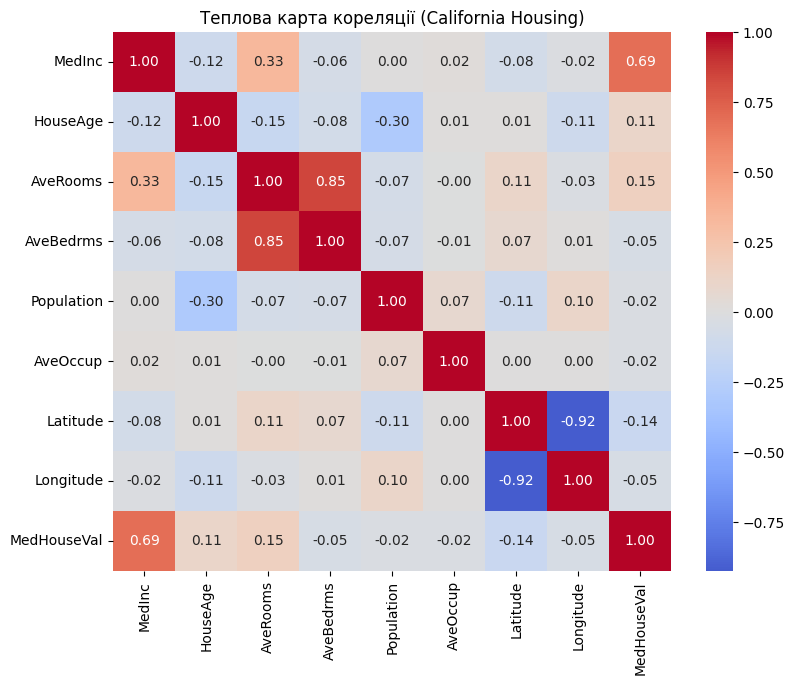

Кварталів з обмеженою вартістю (>= 5.0): 992 (4.8 %)


In [19]:
# 1.6. Кореляція з цільовою змінною (за спаданням) і теплова карта
corr_ch = ch.corr()['MedHouseVal'].drop('MedHouseVal').sort_values(ascending=False)
print('Кореляція з MedHouseVal (за спаданням):')
print(corr_ch)

plt.figure(figsize=(9, 7))
sns.heatmap(ch.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Теплова карта кореляції (California Housing)')
plt.show()

# Особливість датасету: вартість обмежена зверху значенням 5.0 (500 тис. $)
capped = (ch['MedHouseVal'] >= 5.0).sum()
print(f'Кварталів з обмеженою вартістю (>= 5.0): {capped} ({capped / len(ch) * 100:.1f} %)')

In [20]:
# 2. Масштабування ознак
X_ch = ch.drop(columns='MedHouseVal')
y_ch = ch['MedHouseVal']
X_ch_scaled = pd.DataFrame(StandardScaler().fit_transform(X_ch), columns=X_ch.columns)
X_ch_scaled.describe().loc[['mean', 'std']]

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
mean,0.000,0.000,0.000,-0.000,-0.000,0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


In [21]:
# 3. Поділ на тренувальну і тестову вибірки (80 % / 20 %)
# масштабувальник навчаємо лише на тренувальних даних
X_tr_raw, X_te_raw, y_tr_ch, y_te_ch = train_test_split(X_ch, y_ch, test_size=0.2, random_state=RANDOM_STATE)
scaler_ch = StandardScaler().fit(X_tr_raw)
X_tr_ch = pd.DataFrame(scaler_ch.transform(X_tr_raw), columns=X_ch.columns, index=X_tr_raw.index)
X_te_ch = pd.DataFrame(scaler_ch.transform(X_te_raw), columns=X_ch.columns, index=X_te_raw.index)
print('Тренувальна вибірка:', X_tr_ch.shape, ' Тестова вибірка:', X_te_ch.shape)

Тренувальна вибірка: (16512, 8)  Тестова вибірка: (4128, 8)


In [22]:
# 4. Три моделі з підбором оптимальних параметрів за допомогою GridSearchCV (3 блоки, метрика R2)
# (RandomForest на 16 тис. рядків навчається довше за інші - ця комірка може виконуватись кілька хвилин)
cv3 = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
models = {
    'Лінійна регресія': (LinearRegression(), {'fit_intercept': [True, False]}),
    'Ridge': (Ridge(), {'alpha': [0.01, 0.1, 1, 10, 100, 1000]}),
    'RandomForest': (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                     {'n_estimators': [100], 'max_depth': [10, 20, None], 'min_samples_leaf': [1, 4]}),
}
grids = {}
for name, (model, params) in models.items():
    gs = GridSearchCV(model, params, cv=cv3, scoring='r2', n_jobs=-1)
    gs.fit(X_tr_ch, y_tr_ch)
    grids[name] = gs
    print(f'{name}: найкращі параметри {gs.best_params_}, R2 на крос-валідації = {gs.best_score_:.4f}')

Лінійна регресія: найкращі параметри {'fit_intercept': True}, R2 на крос-валідації = 0.6058
Ridge: найкращі параметри {'alpha': 0.01}, R2 на крос-валідації = 0.6058
RandomForest: найкращі параметри {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}, R2 на крос-валідації = 0.7990


In [23]:
# 5. R2 та MSE на тестовій вибірці
preds_ch = {name: gs.best_estimator_.predict(X_te_ch) for name, gs in grids.items()}
res_ch = pd.DataFrame({name: metrics(y_te_ch, p) for name, p in preds_ch.items()}).T.sort_values('R2', ascending=False)
display(res_ch)
best_ch = res_ch.index[0]
print(f"Відповідь: найкраща модель - {best_ch}, R2 = {res_ch.loc[best_ch, 'R2']:.3f}, MSE = {res_ch.loc[best_ch, 'MSE']:.3f}")
print('Коефіцієнти Ridge:', dict(zip(X_ch.columns, grids['Ridge'].best_estimator_.coef_.round(3))))

,R2,MSE,RMSE
RandomForest,0.809,0.253,0.503
Ridge,0.600,0.530,0.728
Лінійна регресія,0.600,0.530,0.728


Відповідь: найкраща модель - RandomForest, R2 = 0.809, MSE = 0.253
Коефіцієнти Ridge: {'MedInc': np.float64(0.842), 'HouseAge': np.float64(0.12), 'AveRooms': np.float64(-0.274), 'AveBedrms': np.float64(0.316), 'Population': np.float64(-0.003), 'AveOccup': np.float64(-0.029), 'Latitude': np.float64(-0.898), 'Longitude': np.float64(-0.872)}


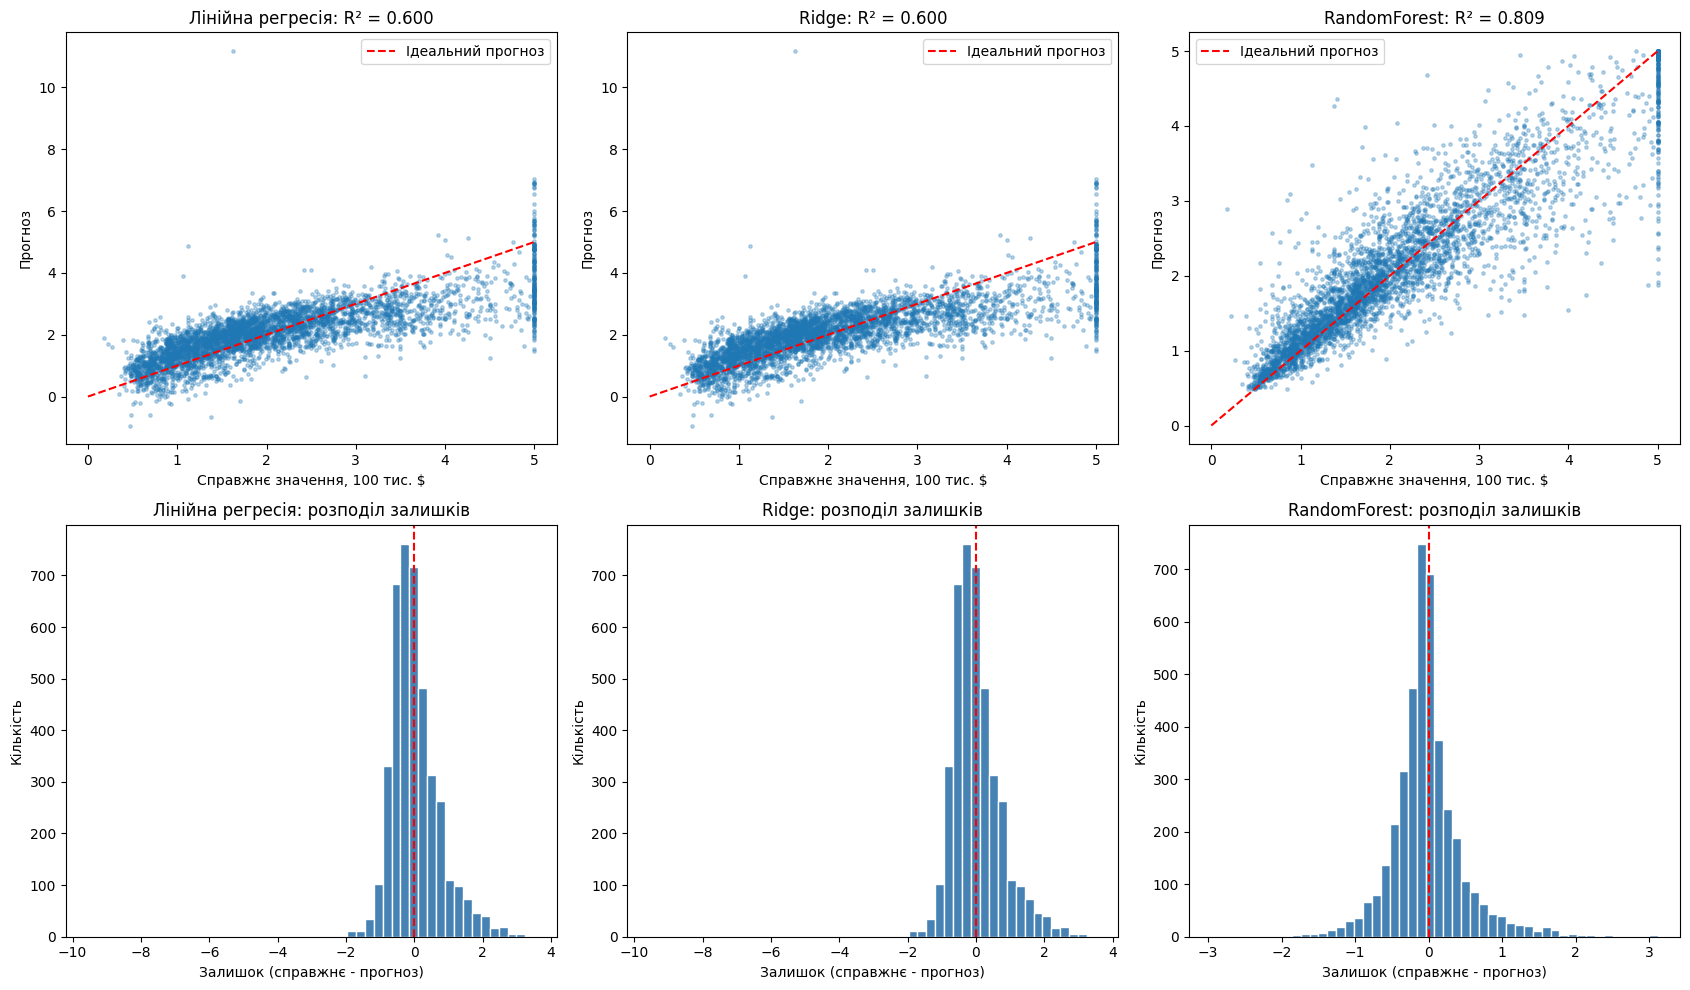

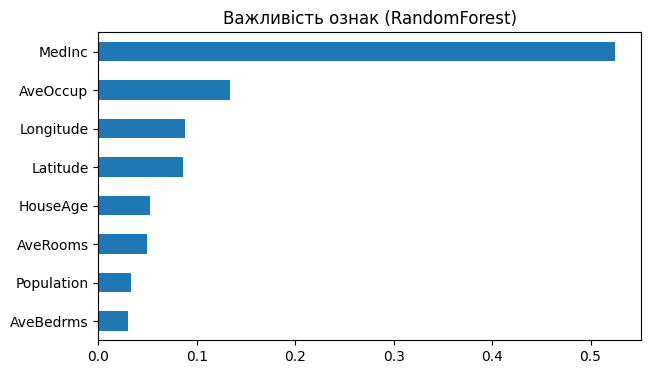

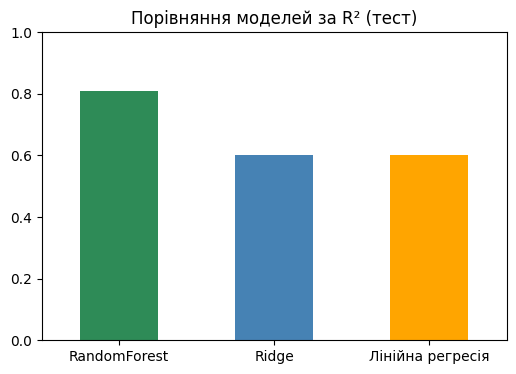

In [24]:
# 5. Графіки: прогноз проти справжніх значень, залишки та важливість ознак
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for col, (name, pred) in enumerate(preds_ch.items()):
    ax = axes[0, col]
    ax.scatter(y_te_ch, pred, s=6, alpha=0.3)
    ax.plot([0, 5], [0, 5], 'r--', label='Ідеальний прогноз')
    ax.set_xlabel('Справжнє значення, 100 тис. $'); ax.set_ylabel('Прогноз')
    ax.set_title(f'{name}: R² = {r2_score(y_te_ch, pred):.3f}'); ax.legend()

    ax = axes[1, col]
    ax.hist(y_te_ch - pred, bins=50, color='steelblue', edgecolor='white')
    ax.axvline(0, color='r', ls='--')
    ax.set_xlabel('Залишок (справжнє - прогноз)'); ax.set_ylabel('Кількість')
    ax.set_title(f'{name}: розподіл залишків')
plt.tight_layout(); plt.show()

pd.Series(grids['RandomForest'].best_estimator_.feature_importances_, index=X_ch.columns).sort_values()\
  .plot.barh(figsize=(7, 4), title='Важливість ознак (RandomForest)')
plt.show()

res_ch['R2'].plot.bar(figsize=(6, 4), rot=0, color=['seagreen', 'steelblue', 'orange'], title='Порівняння моделей за R² (тест)')
plt.ylim(0, 1); plt.show()

In [25]:
# 6. Справжні та прогнозовані значення (перші 15 рядків тестової вибірки)
compare_ch = pd.DataFrame({'Справжнє': y_te_ch.values})
for name, p in preds_ch.items():
    compare_ch[f'Прогноз: {name}'] = p.round(3)
compare_ch.head(15)

,Справжнє,Прогноз: Лінійна регресія,Прогноз: Ridge,Прогноз: RandomForest
0,2.930,2.684,2.684,2.520
1,0.975,0.700,0.700,0.921
2,2.331,2.111,2.111,2.118
3,3.089,2.223,2.223,2.473
4,5.000,4.179,4.179,4.373
5,2.450,2.815,2.815,2.724
6,5.000,3.236,3.236,3.944
7,0.664,0.045,0.045,0.792
8,1.625,1.556,1.556,2.057
9,1.625,2.013,2.013,1.921


### Висновок до завдання 2

Датасет California Housing містить 20 640 житлових кварталів Каліфорнії з 8 числовими ознаками. Цільова змінна `MedHouseVal` — медіанна вартість будинку в сотнях тисяч доларів. Пропусків, дублікатів і бінарних ознак немає, усі стовпці числові. Важлива особливість даних: вартість обмежена зверху значенням 5,0 (500 тис. $), і на цій межі опинилися 992 квартали (4,8 %). Деякі ознаки мають сильні викиди: максимальна середня кількість мешканців `AveOccup` дорівнює 1243 при медіані 2,8.

З вартістю житла найсильніше пов'язаний медіанний дохід мешканців `MedInc` (r = 0,69). Решта ознак мають слабкий зв'язок: кількість кімнат `AveRooms` (r = 0,15), широта `Latitude` (r = −0,14) та вік будинків `HouseAge` (r = 0,11).

Ознаки масштабовано, а дані поділено на тренувальну (16 512) і тестову (4128) вибірки. Параметри трьох моделей підібрано за допомогою GridSearchCV. Для лінійної регресії найкращим виявився варіант з вільним членом. Для Ridge найкращий параметр регуляризації — найменший у сітці, alpha = 0,01. Отже, регуляризація тут не потрібна, і Ridge дає практично ту саму модель, що й звичайна лінійна регресія. Для RandomForest найкращими є 100 дерев без обмеження глибини та з мінімальним розміром листка 1.

Результати на тестовій вибірці:
- лінійна регресія — R² = 0,600, MSE = 0,530;
- Ridge — R² = 0,600, MSE = 0,530;
- RandomForest — R² = 0,809, MSE = 0,253.

Найкращою моделлю є випадковий ліс: він пояснює 81 % мінливості вартості житла, а його середньоквадратична помилка вдвічі менша, ніж у лінійних моделей. Перевага пояснюється тим, що залежність вартості від ознак нелінійна, особливо від координат. Ціна визначається розташуванням (узбережжя, великі міста), а не тим, що широта чи довгота просто зростає. Лінійна модель може врахувати координати лише як «нахил», тому в Ridge вони отримали великі від'ємні коефіцієнти (−0,90 і −0,87), а ліс виділяє конкретні райони. Найважливішою ознакою для лісу є дохід `MedInc` (близько 52 % важливості), далі йдуть `AveOccup` і координати.

Графіки показують і слабкі місця моделей. Лінійні моделі для частини кварталів прогнозують від'ємну вартість, а для одного кварталу — понад 11, що фізично неможливо. Вони також систематично занижують ціну найдорожчих кварталів. Для кварталів з вартістю 5,0 усі моделі дають широкий розкид прогнозів, бо справжня вартість цих будинків може бути вищою за межу. У RandomForest точки розташовані значно ближче до діагоналі ідеального прогнозу, а залишки вужче зосереджені навколо нуля. Отже, для прогнозування вартості житла доцільно використовувати RandomForest.